# Electricity Generation and Energy Source Analysis
**Course:** Exploratory Data Analysis and Visualization (EDAV) - Course-End Project

## About this notebook
This notebook studies how the world makes its electricity and how that has changed. The data is a yearly global electricity file with generation (TWh), share of generation, capacity (GW), emissions and emission intensity for every area, year and energy source.

I follow the order given in the project instructions: data cleaning, analysis, visualization, conclusion. Each question has a short **concept** note, the **code**, and an **insight** written in plain words.

| Q | Task | CO / BL |
|---|------|---------|
| Q1 | Use NumPy to get the average, minimum and maximum yearly generation of every source | CO1, BL3 |
| Q2 | Use Pandas groupby to study how the source mix, fossil share and regions changed | CO2, BL4 |
| Q3 | Handle missing values with fillna and other imputation (done first, before any calculation) | CO3, BL3 |
| Q4 | Group countries by continent and compute descriptive statistics | CO4, BL4 |
| Q5 | Bar plots, line plots and a heatmap to show the main findings | CO5, BL5 |

**Note on order:** Q3 (cleaning) is run first because every other question needs the cleaned data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 100)
pd.set_option('display.max_columns', 30)

## 1. Loading the data
The raw file is loaded once and kept untouched in `raw`. All cleaning is done on a copy called `df`, so I can always go back and compare.

In [2]:
raw = pd.read_csv('release_generation_yearly_global.csv')
df = raw.copy()
print('Rows and columns :', df.shape)
print('Years covered    :', df['Year'].min(), 'to', df['Year'].max())
print('Areas            :', df['Area'].nunique())
print('Area types       :', df['Area type'].value_counts().to_dict())
print('Sources in file  :', df['Electricity source'].nunique())

Rows and columns : (104241, 24)
Years covered    : 1985 to 2025
Areas            : 224
Area types       : {'Country or economy': 97975, 'Region': 6266}
Sources in file  : 17


## 2. Inspecting the data
Before cleaning I look at the columns, the missing values and the duplicates.

In [3]:
print(df.dtypes.value_counts().to_string())
print()
print('Duplicate rows:', df.duplicated().sum())
print()
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame('missing')
missing['percent'] = (missing['missing'] / len(df) * 100).round(1)
print(missing)

float64    11
str         6
bool        6
int64       1

Duplicate rows: 0

                                           missing  percent
Emissions YoY change (%)                     48746     46.8
Emissions intensity (gCO2e/kWh)              40583     38.9
Generation YoY change (%)                    37028     35.5
Capacity (GW)                                28355     27.2
Emissions YoY change (MtCO2e)                 9826      9.4
Share of emissions (%)                        6337      6.1
Emissions (MtCO2e)                            6305      6.0
Continent                                     6266      6.0
ISO 3 code                                    6266      6.0
Ember region                                  6266      6.0
Share of generation YoY change (% points)     3779      3.6
Generation YoY change (TWh)                   3745      3.6
Share of generation (%)                         34      0.0


In [4]:
# The file has a flag that marks summary rows (totals and groups of other rows)
flag_view = df.groupby('Is aggregated source')['Electricity source'].unique()
for flag, names in flag_view.items():
    print('Is aggregated source =', flag)
    print('   ', ', '.join(names))

Is aggregated source = False
    Solar, Wind, Hydro, Bioenergy, Other renewables, Nuclear, Coal, Gas, Other fossil, Net imports
Is aggregated source = True
    Wind and solar, Hydro, bioenergy and other renewables, Renewables, Clean, Fossil, Total generation, Demand


### What I noticed
- Some columns have a lot of gaps, mainly the year-on-year (YoY) columns, **Emissions intensity** and **Capacity**.
- Seven of the "sources" are not real sources. They are summary rows such as *Total generation*, *Renewables* and *Fossil*. *Net imports* is also not a generation source. If I add these to the real sources, the same electricity is counted twice, so they must be removed before any totals are made.
- There are no duplicate rows.

## 3. Q3 - Handling missing values (CO3, BL3)
**Concept.** Missing values can break averages, totals and shares, so I fill them first. A blind fill with the mean would be wrong here, because a gap in this file usually has a reason. My rules are:

| Column | Why it is missing | How I fill it |
|---|---|---|
| ISO 3 code, Continent, Ember region | Region rows have no country | Label such as `Region` / `Not applicable` |
| Emissions | Only the *Demand* summary rows | 0 (demand is not a producing source) |
| Share of generation / emissions | A few rows | Recalculate from generation (or emissions) divided by the area total |
| Capacity | Source has no plant, or capacity not reported | 0 if generation is 0, otherwise estimate from the source's typical capacity factor |
| YoY change (TWh, MtCO2e, % points) | First year of a series | Recalculate with `diff()`, first year set to 0 |
| YoY change (%) | Previous value was 0 so a % is undefined | 0 |
| Emissions intensity | Not given for many rows | Recalculate emissions / generation x 1000 |

I also add a `(was missing)` flag column for every column that had gaps, so filled values can always be traced.

In [5]:
# Step 1: remember which cells were missing
gap_cols = [c for c in df.columns if df[c].isna().any()]
for c in gap_cols:
    df[c + ' (was missing)'] = df[c].isna()
print('Columns that had gaps:', len(gap_cols))

# Step 2: text columns
df['ISO 3 code'] = df['ISO 3 code'].fillna('Region')
df['Continent'] = df['Continent'].fillna('Not applicable')
df['Ember region'] = df['Ember region'].fillna('Not applicable')

# Step 3: emissions - only the Demand rows are empty
df['Emissions (MtCO2e)'] = df['Emissions (MtCO2e)'].fillna(0)

# Step 4: shares - recalculate from the 'Total generation' row of the same area and year
tot = df[df['Electricity source'] == 'Total generation'].set_index(['Area', 'Year'])
key = pd.MultiIndex.from_arrays([df['Area'], df['Year']])
tot_gen = tot['Generation (TWh)'].reindex(key).to_numpy()
tot_em = tot['Emissions (MtCO2e)'].reindex(key).to_numpy()
share_gen = np.where(tot_gen > 0, df['Generation (TWh)'] / tot_gen * 100, 0)
share_em = np.where(tot_em > 0, df['Emissions (MtCO2e)'] / tot_em * 100, 0)
df['Share of generation (%)'] = df['Share of generation (%)'].fillna(pd.Series(share_gen, index=df.index))
df['Share of emissions (%)'] = df['Share of emissions (%)'].fillna(pd.Series(share_em, index=df.index))
print('Share columns still missing:', df[['Share of generation (%)', 'Share of emissions (%)']].isna().sum().sum())

Columns that had gaps: 13
Share columns still missing: 0


In [6]:
# Step 5: capacity
real = df[(~df['Is aggregated source']) & (df['Electricity source'] != 'Net imports')]
ok = real[(real['Capacity (GW)'] > 0) & (real['Generation (TWh)'] > 0)]
# capacity factor = actual generation / (capacity x hours in a year)
cf = (ok['Generation (TWh)'] * 1000 / (ok['Capacity (GW)'] * 8760)).groupby(ok['Electricity source']).median().clip(upper=1)
print('Typical capacity factor by source:')
print(cf.round(2).to_string())

is_real = ~(df['Is aggregated source'] | (df['Electricity source'] == 'Net imports'))
need = df['Capacity (GW)'].isna() & is_real          # real sources with no capacity value
print()
print('Real-source rows with missing capacity :', need.sum())
print('   of which generation is 0 (no plant)  :', (need & (df['Generation (TWh)'] == 0)).sum())
print('   of which there is generation         :', (need & (df['Generation (TWh)'] > 0)).sum())

estimate = df['Generation (TWh)'] * 1000 / (8760 * df['Electricity source'].map(cf))
df.loc[need & (df['Generation (TWh)'] > 0), 'Capacity (GW)'] = estimate
df['Capacity (GW)'] = df['Capacity (GW)'].fillna(0)     # no generation -> no capacity; summary rows -> 0

Typical capacity factor by source:
Electricity source
Bioenergy           0.50
Coal                0.56
Gas                 0.42
Hydro               0.39
Nuclear             0.81
Other fossil        0.35
Other renewables    0.69
Solar               0.13
Wind                0.24

Real-source rows with missing capacity : 11974
   of which generation is 0 (no plant)  : 7223
   of which there is generation         : 4751


In [7]:
# Step 6: YoY columns and emissions intensity
df = df.sort_values(['Area', 'Electricity source', 'Year']).reset_index(drop=True)
grp = df.groupby(['Area', 'Electricity source'])
df['Generation YoY change (TWh)'] = df['Generation YoY change (TWh)'].fillna(grp['Generation (TWh)'].diff())
df['Emissions YoY change (MtCO2e)'] = df['Emissions YoY change (MtCO2e)'].fillna(grp['Emissions (MtCO2e)'].diff())
pp = 'Share of generation YoY change (% points)'
df[pp] = df[pp].fillna(grp['Share of generation (%)'].diff())

intensity_calc = np.where(df['Generation (TWh)'] > 0, df['Emissions (MtCO2e)'] / df['Generation (TWh)'] * 1000, 0)
df['Emissions intensity (gCO2e/kWh)'] = df['Emissions intensity (gCO2e/kWh)'].fillna(pd.Series(intensity_calc, index=df.index))

# Step 7: whatever is still empty (first year of a series, undefined % changes) becomes 0
num_cols = df.select_dtypes('number').columns
df[num_cols] = df[num_cols].fillna(0)

In [8]:
# Check: no missing values should remain in the data columns
flag_cols = [c for c in df.columns if c.endswith('(was missing)')]
data_cols = [c for c in df.columns if c not in flag_cols]
print('Missing values left in data columns:', int(df[data_cols].isna().sum().sum()))
print()
print('How many cells were filled in each column:')
filled = df[flag_cols].sum().sort_values(ascending=False)
filled.index = [c.replace(' (was missing)', '') for c in filled.index]
print(filled.to_string())

Missing values left in data columns: 0

How many cells were filled in each column:
Emissions YoY change (%)                     48746
Emissions intensity (gCO2e/kWh)              40583
Generation YoY change (%)                    37028
Capacity (GW)                                28355
Emissions YoY change (MtCO2e)                 9826
Share of emissions (%)                        6337
Emissions (MtCO2e)                            6305
Continent                                     6266
ISO 3 code                                    6266
Ember region                                  6266
Share of generation YoY change (% points)     3779
Generation YoY change (TWh)                   3745
Share of generation (%)                         34


**Insight.** Every data column is now complete, and nothing was guessed silently: each filled cell can be found through its flag column. The main judgement call was capacity. Zero is correct where a source produces nothing, but where a source did produce electricity and the capacity was simply not reported, I estimated it from the typical capacity factor of that source instead of leaving a false zero.

## 4. Separating real sources from summary rows
After cleaning, I keep only the nine real generation sources. I then make three working tables: the whole `sources` table, the `countries` table, and the `world` rows. Regions (for example Asia or the EU) are kept separately in `regions`.

In [9]:
not_a_source = df['Is aggregated source'] | (df['Electricity source'] == 'Net imports')
sources = df[~not_a_source].copy()

countries = sources[sources['Area type'] == 'Country or economy']
regions = sources[sources['Area type'] == 'Region']
world = sources[sources['Area'] == 'World']

FOSSIL = ['Coal', 'Gas', 'Other fossil']
print('Rows kept             :', len(sources), 'of', len(df))
print('Real sources          :', sorted(sources['Electricity source'].unique()))
print('Countries / economies :', countries['Area'].nunique())
print('Regions               :', regions['Area'].nunique())
print('World rows            :', len(world), '| years', world['Year'].min(), 'to', world['Year'].max())

# Consistency check: do the nine sources add up to the reported world total?
check_year = 2024
reported = df[(df['Area'] == 'World') & (df['Year'] == check_year) & (df['Electricity source'] == 'Total generation')]['Generation (TWh)'].iloc[0]
summed = world[world['Year'] == check_year]['Generation (TWh)'].sum()
print(f'World {check_year}: sum of sources = {summed:,.1f} TWh | reported total = {reported:,.1f} TWh')

Rows kept             : 54541 of 104241
Real sources          : ['Bioenergy', 'Coal', 'Gas', 'Hydro', 'Nuclear', 'Other fossil', 'Other renewables', 'Solar', 'Wind']
Countries / economies : 209
Regions               : 15
World rows            : 234 | years 2000 to 2025
World 2024: sum of sources = 31,070.7 TWh | reported total = 31,070.7 TWh


## 5. Q1 - NumPy statistics of yearly generation (CO1, BL3)
**Concept.** I put the world's yearly generation for each source into a NumPy array (rows = years, columns = sources). NumPy functions along `axis=0` then give the mean, minimum and maximum of every source in one step.

In [10]:
gen = world.pivot_table(index='Year', columns='Electricity source', values='Generation (TWh)', aggfunc='sum').sort_index()
years = gen.index.to_numpy()
arr = gen.to_numpy()                      # shape: (number of years, number of sources)
print('Array shape (years x sources):', arr.shape)

stats = pd.DataFrame({
    'mean':      np.mean(arr, axis=0),
    'min':       np.min(arr, axis=0),
    'max':       np.max(arr, axis=0),
    'std':       np.std(arr, axis=0),
    'peak_year': years[np.argmax(arr, axis=0)],
    'first':     arr[0],
    'last':      arr[-1],
}, index=gen.columns)
stats['change_x'] = (stats['last'] / stats['first']).round(1)
print()
print(stats.round(1).sort_values('mean', ascending=False).to_string())

Array shape (years x sources): (26, 9)

                      mean     min      max     std  peak_year   first     last  change_x
Electricity source                                                                       
Coal                8706.6  5841.1  10652.4  1499.4       2024  5841.1  10606.8       1.8
Gas                 5053.1  2747.1   6920.5  1320.4       2025  2747.1   6920.5       2.5
Hydro               3598.2  2566.6   4462.9   643.8       2024  2632.6   4446.2       1.7
Nuclear             2647.2  2431.9   2805.0    98.0       2025  2540.5   2805.0       1.1
Other fossil        1089.4   793.4   1329.1   163.1       2000  1329.1    889.0       0.7
Wind                 866.7    31.2   2705.1   834.1       2025    31.2   2705.1      86.8
Solar                490.8     1.1   2806.6   732.5       2025     1.1   2806.6    2593.9
Bioenergy            393.9   154.6    652.4   166.7       2025   159.0    652.4       4.1
Other renewables      66.7    43.6     91.5    16.2       20

In [11]:
# Total generation and its yearly growth, again with NumPy
total = arr.sum(axis=1)
growth = np.diff(total) / total[:-1] * 100          # % change from one year to the next
n_years = years[-1] - years[0]
cagr = ((total[-1] / total[0]) ** (1 / n_years) - 1) * 100

print(f'Total generation {years[0]}: {total[0]:,.0f} TWh')
print(f'Total generation {years[-1]}: {total[-1]:,.0f} TWh')
print(f'Average yearly growth       : {growth.mean():.2f} %')
print(f'Compound annual growth rate : {cagr:.2f} %')
print(f'Fastest year  : {years[1:][np.argmax(growth)]} ({growth.max():.1f} %)')
print(f'Slowest year  : {years[1:][np.argmin(growth)]} ({growth.min():.1f} %)')
print('Years with a fall in generation:', years[1:][growth < 0].tolist())

Total generation 2000: 15,325 TWh
Total generation 2025: 31,923 TWh
Average yearly growth       : 2.99 %
Compound annual growth rate : 2.98 %
Fastest year  : 2010 (6.6 %)
Slowest year  : 2009 (-0.8 %)
Years with a fall in generation: [2009, 2020]


**Insight (Q1).** Coal and gas have the highest averages, and coal also reaches the highest single-year peak. Solar and wind have the smallest averages but by far the biggest jump from their first to their last year, which is why their `change_x` is so large. Total generation grew in every year except 2009 and 2020, which are the two dips in the output above (the data itself does not say why). Average growth is about 3 % a year, so world generation roughly doubled in 25 years.

## 6. Q2 - Pandas groupby analysis of the source mix (CO2, BL4)
**Concept.** `groupby` splits the table into groups (a year, a region), applies a calculation (sum, mean) to each group and joins the results. I use it for the fossil and low-carbon split, the share of each source, and a comparison of regions.

In [12]:
# Fossil vs low-carbon generation in the world, by year
w = world.assign(group=np.where(world['Electricity source'].isin(FOSSIL), 'Fossil', 'Low-carbon'))
by_group = w.groupby(['Year', 'group'])['Generation (TWh)'].sum().unstack()
by_group['Fossil share (%)'] = by_group['Fossil'] / by_group[['Fossil', 'Low-carbon']].sum(axis=1) * 100

sw = world[world['Electricity source'].isin(['Solar', 'Wind'])].groupby('Year')['Generation (TWh)'].sum()
by_group['Solar+Wind share (%)'] = sw / by_group[['Fossil', 'Low-carbon']].sum(axis=1) * 100

print(by_group.loc[[2000, 2005, 2010, 2015, 2020, 2024, 2025]].round(1).to_string())

group   Fossil  Low-carbon  Fossil share (%)  Solar+Wind share (%)
Year                                                              
2000    9917.3      5408.0              64.7                   0.2
2005   12165.8      6017.8              66.9                   0.6
2010   14399.0      6928.2              67.5                   1.8
2015   16010.5      8052.9              66.5                   4.5
2020   16697.4     10105.7              62.3                   9.1
2024   18442.0     12628.7              59.4                  15.0
2025   18416.3     13506.9              57.7                  17.3


In [13]:
# Share of every source in selected years
snap = [2000, 2010, 2020, 2025]
mix = world[world['Year'].isin(snap)].pivot_table(index='Electricity source', columns='Year', values='Generation (TWh)', aggfunc='sum')
mix_share = (mix / mix.sum() * 100).round(1)
order = ['Coal', 'Gas', 'Other fossil', 'Nuclear', 'Hydro', 'Bioenergy', 'Other renewables', 'Wind', 'Solar']
mix_share = mix_share.loc[order]
print(mix_share.to_string())

Year                2000  2010  2020  2025
Electricity source                        
Coal                38.1  39.9  35.5  33.2
Gas                 17.9  22.6  23.9  21.7
Other fossil         8.7   5.0   3.0   2.8
Nuclear             16.6  12.8   9.9   8.8
Hydro               17.2  16.1  16.2  13.9
Bioenergy            1.0   1.5   2.1   2.0
Other renewables     0.3   0.3   0.3   0.3
Wind                 0.2   1.6   5.9   8.5
Solar                0.0   0.2   3.2   8.8


In [14]:
# Regions: growth from 2000 to 2024 and fossil share in 2024
r = regions[regions['Year'].isin([2000, 2024])]
reg_total = r.groupby(['Area', 'Year'])['Generation (TWh)'].sum().unstack()
reg_total['Growth (%)'] = (reg_total[2024] / reg_total[2000] - 1) * 100

r24 = regions[regions['Year'] == 2024]
fossil_24 = r24[r24['Electricity source'].isin(FOSSIL)].groupby('Area')['Generation (TWh)'].sum()
reg_total['Fossil share 2024 (%)'] = fossil_24 / reg_total[2024] * 100
reg_total = reg_total.rename(columns={2000: 'TWh 2000', 2024: 'TWh 2024'})
print(reg_total.sort_values('TWh 2024', ascending=False).round(0).astype({'Growth (%)': int}).to_string())

Year                         TWh 2000  TWh 2024  Growth (%)  Fossil share 2024 (%)
Area                                                                              
World                         15325.0   31071.0         103                   59.0
G20                           13077.0   26133.0         100                   58.0
Asia                           4246.0   16208.0         282                   66.0
OECD                           9620.0   11199.0          16                   48.0
G7                             7254.0    7657.0           6                   50.0
Europe                         4478.0    5093.0          14                   39.0
North America                  4406.0    5034.0          14                   54.0
EU                             2622.0    2772.0           6                   29.0
MENA                            625.0    2009.0         222                   91.0
Latin America and Caribbean    1008.0    1871.0          86                   36.0
Midd

**Insight (Q2).** The fossil share of world electricity rose from 64.7 % in 2000 to a peak of about 68.4 % in 2007 (it was almost as high, 68.3 %, in 2012) and has fallen steadily since, reaching 57.7 % in 2025. Over the same time solar and wind moved from 0.2 % to 17.3 % of the mix. Fossil generation fell slightly in 2025 (by about 26 TWh), as it also did in 2009, 2015, 2019 and 2020. In 2025 total generation still grew by about 2.7 %, so all of that growth came from low-carbon sources. The regional table shows that growth is very uneven: Asia and the fast-growing regions added a huge amount of electricity, while the EU, North America and the G7 grew only a little. Regions like the Middle East and MENA are still almost fully fossil, while the EU and Latin America are far cleaner. (Some regions overlap, for example Asia and ASEAN, so the rows should not be added together.)

## 7. Q4 - Descriptive statistics by continent and country (CO4, BL4)
**Concept.** I build one row per country for 2024 with its generation by source, then group by continent. For each group I count the countries and compute total, mean and median generation and the fossil share.

In [15]:
c24 = countries[countries['Year'] == 2024]
by_country = c24.pivot_table(index=['Area', 'Continent'], columns='Electricity source', values='Generation (TWh)', aggfunc='sum').fillna(0)
by_country['total'] = by_country.sum(axis=1)
by_country = by_country[by_country['total'] > 0].reset_index()
by_country['fossil_share'] = by_country[FOSSIL].sum(axis=1) / by_country['total'] * 100
by_country['solar_wind_share'] = by_country[['Solar', 'Wind']].sum(axis=1) / by_country['total'] * 100
print('Countries with generation in 2024:', len(by_country))

cont = by_country.groupby('Continent').agg(
    countries=('Area', 'count'),
    total_TWh=('total', 'sum'),
    mean_TWh=('total', 'mean'),
    median_TWh=('total', 'median'),
    avg_fossil=('fossil_share', 'mean'))
cont['wtd_fossil'] = by_country.groupby('Continent')[FOSSIL].sum().sum(axis=1) / cont['total_TWh'] * 100
print()
print(cont.sort_values('total_TWh', ascending=False).round(1).to_string())

Countries with generation in 2024: 193

               countries  total_TWh  mean_TWh  median_TWh  avg_fossil  wtd_fossil
Continent                                                                        
Asia                  49    18108.8     369.6        49.1        68.5        68.3
North America         27     5571.0     206.3         4.5        67.8        55.5
Europe                40     4649.4     116.2        38.1        35.8        37.6
South America         13     1328.0     102.2        42.4        39.1        20.9
Africa                50      961.4      19.2         3.4        59.1        74.3
Oceania               14      340.2      24.3         0.4        68.1        58.1


In [16]:
# How are fossil shares spread across countries?
print(by_country['fossil_share'].describe().round(1).to_string())
bands = pd.cut(by_country['fossil_share'], bins=[-0.1, 25, 50, 75, 90, 100.1],
               labels=['0-25 %', '25-50 %', '50-75 %', '75-90 %', '90-100 %'])
print()
print('Number of countries by fossil share band:')
print(bands.value_counts().sort_index().to_string())

count    193.0
mean      57.2
std       33.2
min        0.0
25%       26.5
50%       64.2
75%       86.7
max      100.0

Number of countries by fossil share band:
fossil_share
0-25 %      46
25-50 %     31
50-75 %     38
75-90 %     36
90-100 %    42


In [17]:
# The ten biggest generators of 2024
top10 = by_country.sort_values('total', ascending=False).head(10).set_index('Area')
top10 = top10[['Continent', 'total', 'fossil_share', 'solar_wind_share']].round(1)
top10.columns = ['Continent', 'Total TWh', 'Fossil %', 'Solar+Wind %']
print(top10.to_string())

                   Continent  Total TWh  Fossil %  Solar+Wind %
Area                                                           
China                   Asia    10025.0      62.3          18.3
United States  North America     4391.0      58.1          17.2
India                   Asia     2035.2      77.6          11.0
Russia                Europe     1209.3      64.1           0.6
Japan                   Asia     1015.0      68.9          10.6
Brazil         South America      751.3       9.9          23.7
Canada         North America      642.6      22.6           8.7
South Korea             Asia      627.8      59.5           6.6
France                Europe      564.5       5.1          12.9
Indonesia               Asia      507.3      85.2           0.4


In [18]:
# Carbon intensity by source (world, 2024) and India's mix
w24 = world[world['Year'] == 2024].set_index('Electricity source')
ci = w24[['Generation (TWh)', 'Emissions (MtCO2e)', 'Emissions intensity (gCO2e/kWh)']].round(0).sort_values('Emissions intensity (gCO2e/kWh)', ascending=False)
ci.columns = ['TWh', 'MtCO2e', 'gCO2e/kWh']
print(ci.to_string())

india = countries[(countries['Area'] == 'India') & (countries['Year'] == 2024)].set_index('Electricity source')['Generation (TWh)']
print()
print(f"India 2024 total: {india.sum():,.0f} TWh")
print((india / india.sum() * 100).round(1).sort_values(ascending=False).to_string())

                        TWh  MtCO2e  gCO2e/kWh
Electricity source                            
Coal                10652.0  9631.0      904.0
Other fossil          896.0   591.0      660.0
Gas                  6893.0  4081.0      592.0
Bioenergy             635.0   138.0      218.0
Solar                2161.0   103.0       48.0
Other renewables       88.0     3.0       38.0
Hydro                4463.0   106.0       24.0
Wind                 2506.0    29.0       12.0
Nuclear              2775.0    15.0        5.0

India 2024 total: 2,035 TWh
Electricity source
Coal            74.6
Hydro            7.7
Solar            7.0
Wind             4.0
Gas              2.8
Nuclear          2.7
Bioenergy        1.1
Other fossil     0.2


**Insight (Q4).** Asia is the biggest generating continent by far, with about 18,100 of the 31,000 TWh. The spread of fossil share between countries is wide: 46 countries get less than a quarter of their electricity from fossil fuels, while 42 get more than 90 %. The average (57 %) hides this split. The ten largest generators are not equally clean: France (5 %) and Brazil (10 %) are very low, while Indonesia (85 %) and India (78 %) are very high. Coal has the highest emission intensity (about 900 gCO2e/kWh), about 1.5 times gas. Solar, wind, hydro and nuclear are not exactly zero, probably because the data includes small life-cycle emissions. India's own mix is 75 % coal.

## 8. Q5 - Visualization (CO5, BL5)
**Concept.** I keep the charts few and simple, one for each main question: how generation grew, how the mix changed, who generates most, how regions differ, and whether electricity got cleaner. Every chart has a title, labelled axes and units.

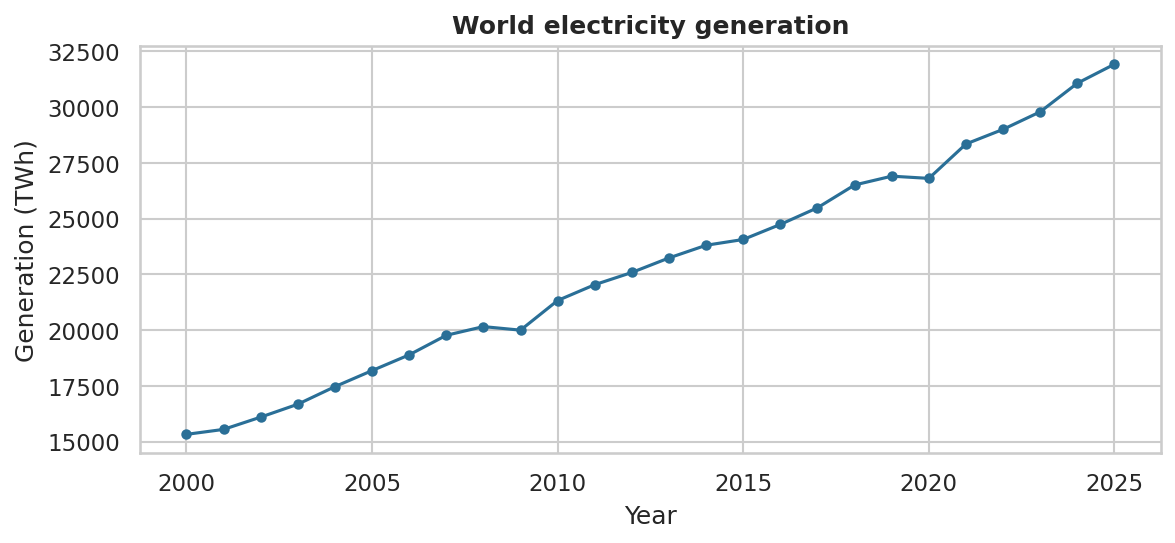

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(gen.index, total, marker='o', ms=4, color='#2a6f97')
ax.set_xlabel('Year'); ax.set_ylabel('Generation (TWh)')
ax.set_title('World electricity generation', fontweight='bold')
plt.tight_layout(); plt.show()

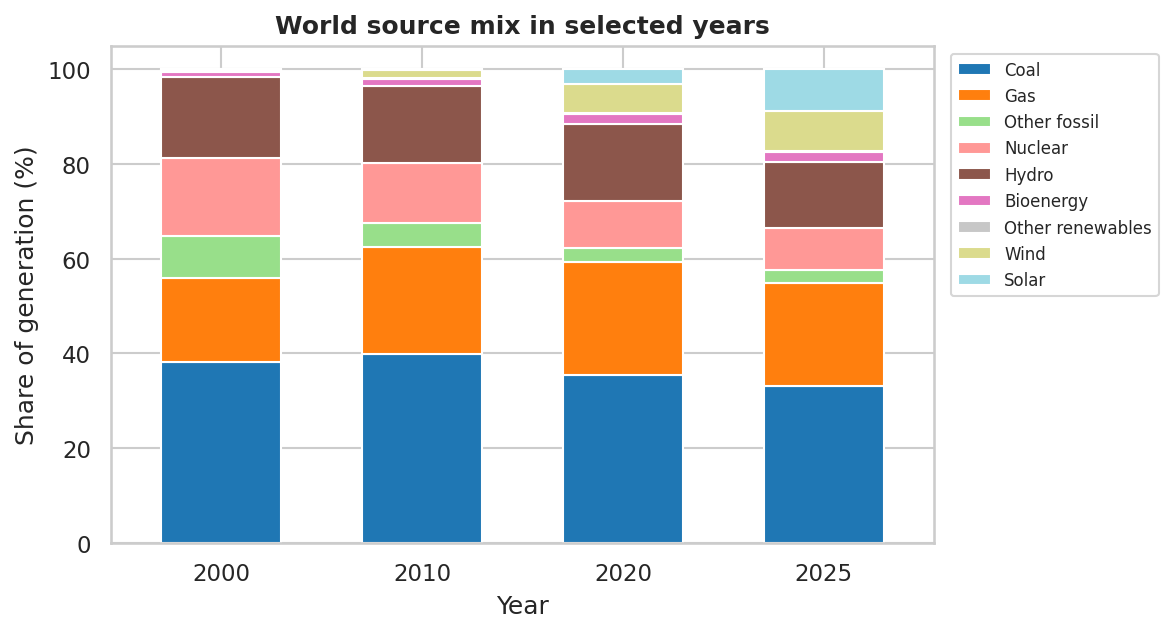

In [20]:
share_all = world[world['Year'].isin(snap)].pivot_table(index='Year', columns='Electricity source', values='Generation (TWh)', aggfunc='sum')
share_all = share_all[order].div(share_all.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 4.4))
share_all.plot(kind='bar', stacked=True, ax=ax, colormap='tab20', width=0.6)
ax.set_xlabel('Year'); ax.set_ylabel('Share of generation (%)')
ax.set_title('World source mix in selected years', fontweight='bold')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

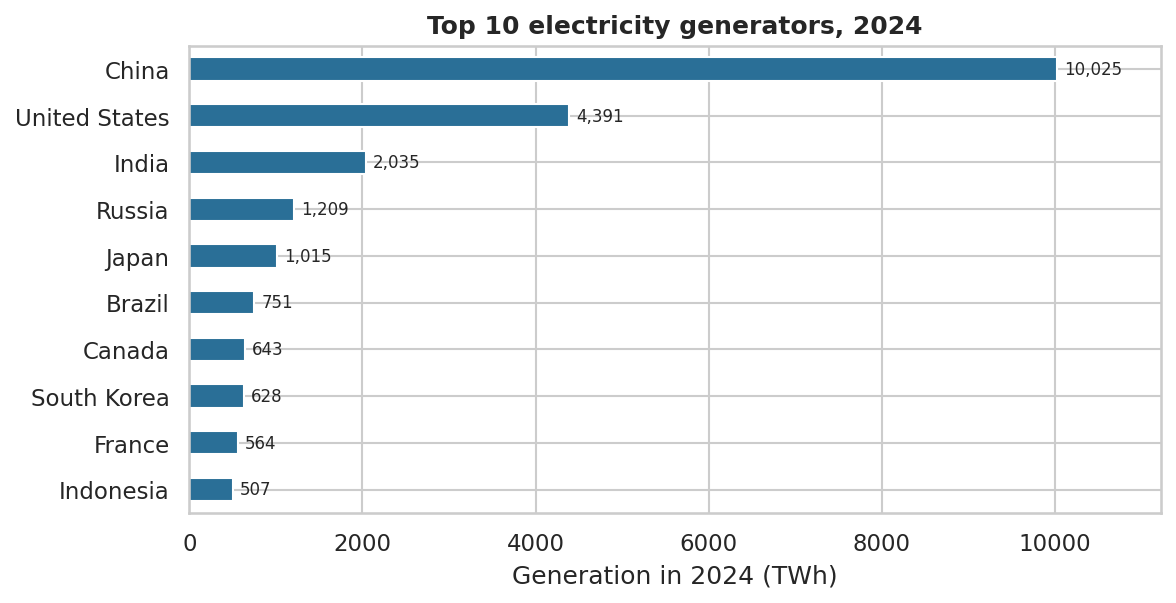

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
top10['Total TWh'].sort_values().plot(kind='barh', ax=ax, color='#2a6f97')
for i, v in enumerate(top10['Total TWh'].sort_values()):
    ax.text(v + 80, i, f'{v:,.0f}', va='center', fontsize=8)
ax.set_xlabel('Generation in 2024 (TWh)'); ax.set_ylabel('')
ax.set_title('Top 10 electricity generators, 2024', fontweight='bold')
ax.set_xlim(0, top10['Total TWh'].max() * 1.12)
plt.tight_layout(); plt.show()

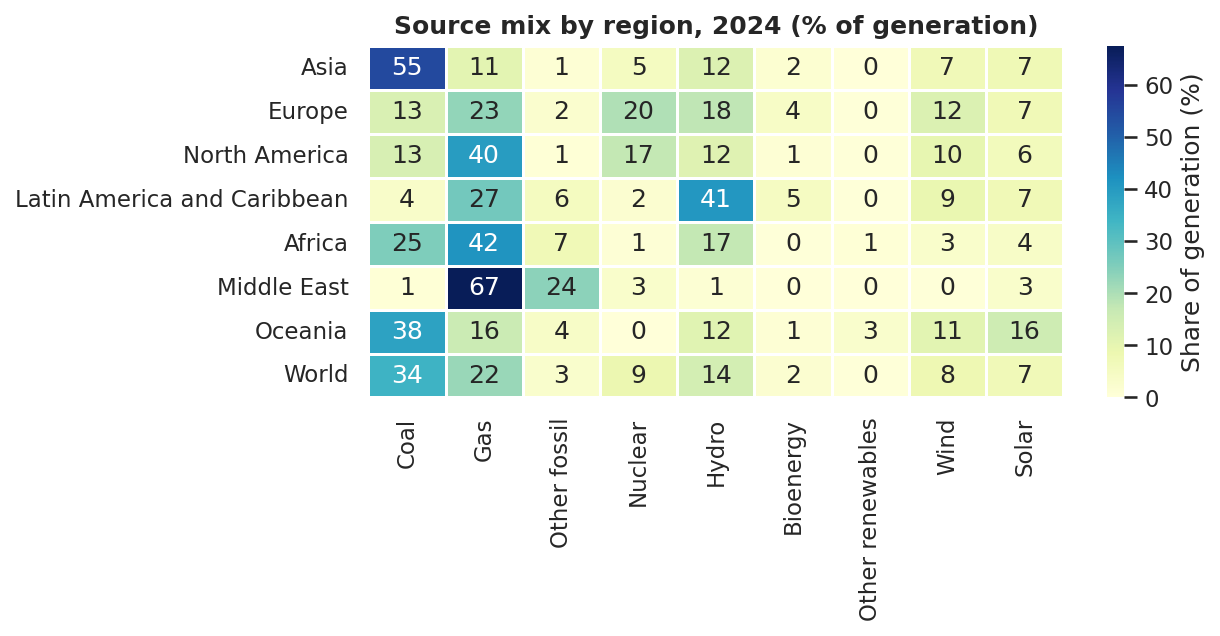

In [22]:
geo = ['Asia', 'Europe', 'North America', 'Latin America and Caribbean', 'Africa', 'Middle East', 'Oceania', 'World']
h = regions[(regions['Year'] == 2024) & (regions['Area'].isin(geo))].pivot_table(index='Area', columns='Electricity source', values='Generation (TWh)', aggfunc='sum')
h = (h[order].div(h[order].sum(axis=1), axis=0) * 100).loc[geo]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
sns.heatmap(h, annot=True, fmt='.0f', cmap='YlGnBu', linewidths=.5, cbar_kws={'label': 'Share of generation (%)'}, ax=ax)
ax.set_title('Source mix by region, 2024 (% of generation)', fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

Year
2000    528.0
2005    544.0
2010    544.0
2015    534.0
2020    494.0
2024    473.0
2025    460.0


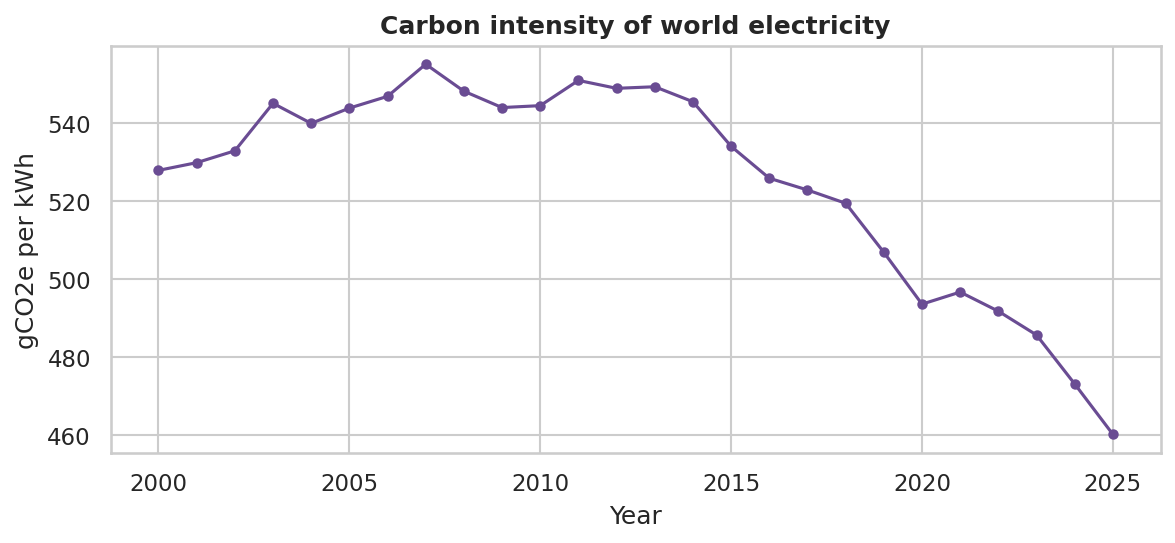

In [23]:
ci_year = world.groupby('Year').agg(em=('Emissions (MtCO2e)', 'sum'), g=('Generation (TWh)', 'sum'))
ci_year['intensity'] = ci_year['em'] / ci_year['g'] * 1000
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ci_year.index, ci_year['intensity'], marker='o', ms=4, color='#6a4c93')
ax.set_xlabel('Year'); ax.set_ylabel('gCO2e per kWh')
ax.set_title('Carbon intensity of world electricity', fontweight='bold')
plt.tight_layout(); plt.show()
print(ci_year['intensity'].loc[[2000, 2005, 2010, 2015, 2020, 2024, 2025]].round(0).to_string())

**Insight (Q5).** The line chart shows steady growth with no break. The stacked bars show coal staying large while solar and wind grow in the later years. The top-10 bar chart shows how far ahead the biggest generators are. The heatmap shows that regions have very different mixes. The intensity chart shows that electricity got cleaner per unit, but the change is slow.

## 9. Conclusion
- World electricity generation has more than doubled since 2000.
- Fossil sources still supply well over half of it, but their share is falling while solar and wind are rising fast.
- Countries and regions are very different. Total size does not tell us how clean a grid is.
- The carbon intensity of electricity is lower than in 2000, but it moves slowly.
- India is a large system that still depends mostly on coal.

### Limitations
- Capacity for some early rows is an estimate, based on typical capacity factors.
- The newest year can still be revised by the data publisher.
- The data shows what happened, not why it happened.
- Overlapping regions (such as Asia and ASEAN) cannot be added together.